# Esercitazione 4 — Alberi Decisionali e Random Forest

Un **Decision Tree** classifica un campione ponendo una sequenza di domande sulle feature (regole *IF-THEN-ELSE*), fino a raggiungere una foglia che contiene la classe predetta. È un modello **white-box**: le regole sono leggibili e spiegabili.

L'algoritmo (CART) sceglie a ogni nodo la divisione che **riduce maggiormente l'impurità** dei nodi figli:

- **Gini:** $G = 1 - \sum_k p_k^2$
- **Entropia:** $H = -\sum_k p_k \log_2 p_k$

dove $p_k$ è la frazione di campioni di classe $k$ nel nodo (impurità 0 = nodo puro).

**Contenuti:** 1) fondamenti e visualizzazione · 2) overfitting e pruning · 3) feature importance · 4) Random Forest.

> Gli alberi **non richiedono Feature Scaling**: le soglie di split sono invarianti a trasformazioni monotone delle feature, quindi `StandardScaler` qui non serve (a differenza di KNN e SVM).

## 0. Setup e importazioni

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, mean_squared_error

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # seme fisso per la riproducibilità

# Sezione 1 — Fondamenti del Decision Tree (classificazione)

## 1.1 Caricamento dati e split 70/30

In [2]:
iris = load_iris()
X, y = iris.data, iris.target
feature_names = iris.feature_names
class_names = iris.target_names

# stratify=y mantiene le proporzioni delle classi in train e test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (105, 4) | Test: (45, 4)


## 1.2 Gini vs Entropia
Addestriamo due alberi identici tranne per il criterio. Di solito le prestazioni sono molto simili: Gini è un po' più veloce (niente logaritmo), l'entropia tende a produrre split leggermente più bilanciati.

In [3]:
modelli = {
    "gini": DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE),
    "entropy": DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE),
}
preds = {}
for nome, m in modelli.items():
    m.fit(X_train, y_train)
    preds[nome] = m.predict(X_test)
    print(f"===== criterion = {nome} =====")
    print(f"Accuracy test: {accuracy_score(y_test, preds[nome]):.4f} | profondità: {m.get_depth()} | foglie: {m.get_n_leaves()}")
    print("Matrice di confusione:\n", confusion_matrix(y_test, preds[nome]))
    print(classification_report(y_test, preds[nome], target_names=class_names))

===== criterion = gini =====
Accuracy test: 0.9333 | profondità: 5 | foglie: 8
Matrice di confusione:
 [[15  0  0]
 [ 0 12  3]
 [ 0  0 15]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.80      0.89        15
   virginica       0.83      1.00      0.91        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45

===== criterion = entropy =====
Accuracy test: 0.8889 | profondità: 6 | foglie: 8
Matrice di confusione:
 [[15  0  0]
 [ 0 13  2]
 [ 0  3 12]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.81      0.87      0.84        15
   virginica       0.86      0.80      0.83        15

    accuracy                           0.89        45
   macro avg       0.89      0.89      0.89        45
weighted a

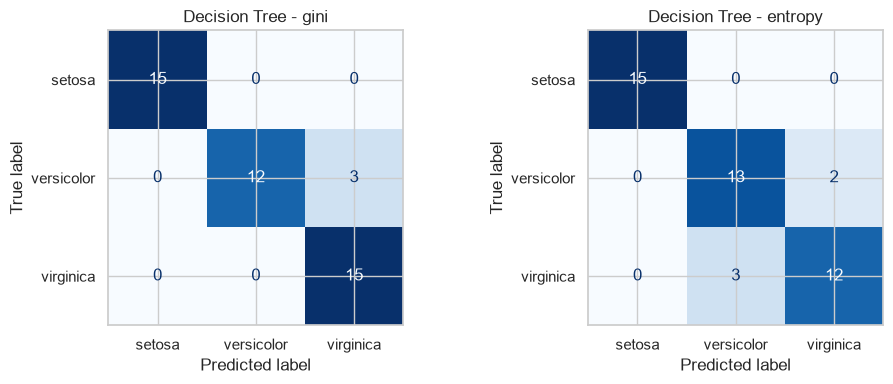

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nome, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=class_names, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Decision Tree - {nome}")
plt.tight_layout(); plt.show()

## 1.3 Visualizzazione dell'albero (white-box)
Ogni nodo mostra: la **regola di split** (`feature <= soglia`), l'impurità (`gini`), il numero di campioni, la distribuzione `value` per classe e la classe maggioritaria. Il colore (`filled=True`) indica la classe prevalente; più è intenso, più il nodo è puro.

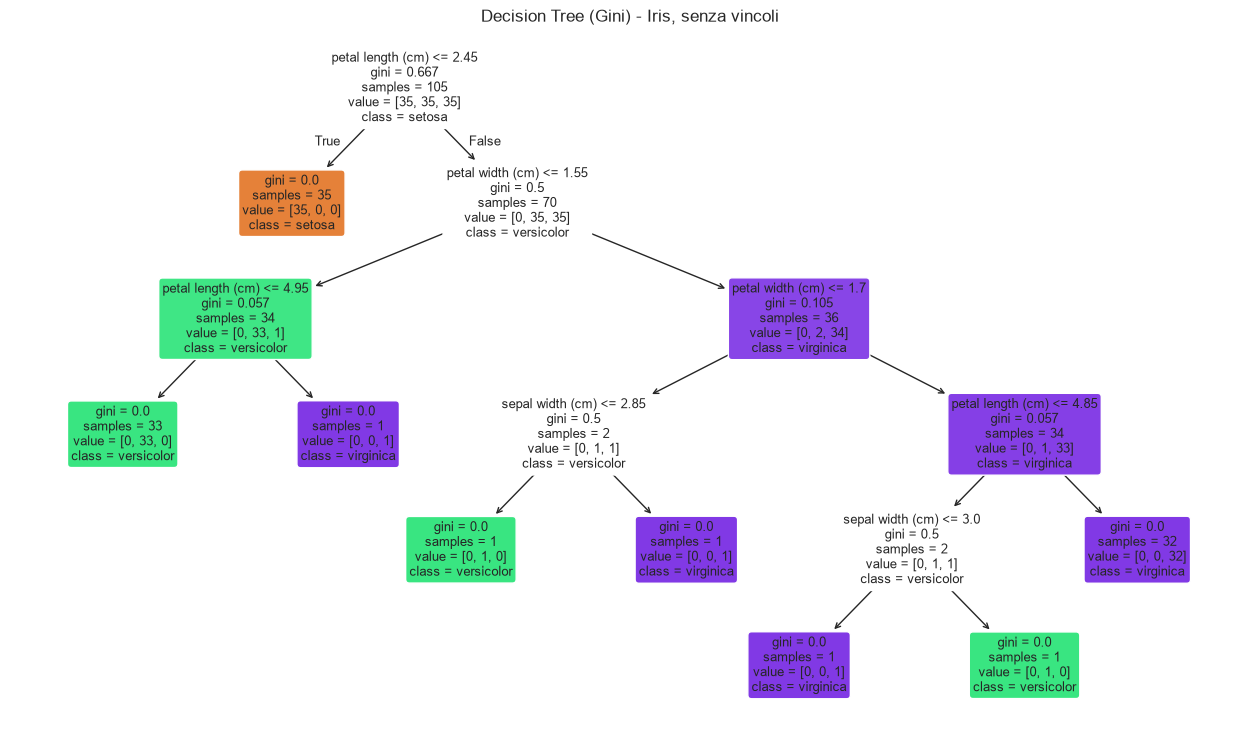

In [5]:
tree_gini = modelli["gini"]
plt.figure(figsize=(16, 9))
plot_tree(tree_gini, feature_names=feature_names, class_names=list(class_names),
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (Gini) - Iris, senza vincoli")
plt.show()

### Regole in forma testuale (`export_text`)

In [6]:
print(export_text(tree_gini, feature_names=feature_names))

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.55
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.55
|   |   |--- petal width (cm) <= 1.70
|   |   |   |--- sepal width (cm) <= 2.85
|   |   |   |   |--- class: 1
|   |   |   |--- sepal width (cm) >  2.85
|   |   |   |   |--- class: 2
|   |   |--- petal width (cm) >  1.70
|   |   |   |--- petal length (cm) <= 4.85
|   |   |   |   |--- sepal width (cm) <= 3.00
|   |   |   |   |   |--- class: 2
|   |   |   |   |--- sepal width (cm) >  3.00
|   |   |   |   |   |--- class: 1
|   |   |   |--- petal length (cm) >  4.85
|   |   |   |   |--- class: 2



Leggi l'albero come regole: ad esempio, la radice separa quasi sempre la *setosa* con una soglia sulla lunghezza/larghezza del petalo; versicolor e virginica richiedono ulteriori domande.

### Predizione di un singolo campione: il percorso nell'albero

In [7]:
campione = X_test[:1]
percorso = tree_gini.decision_path(campione).indices   # nodi attraversati
foglia = tree_gini.apply(campione)[0]
t = tree_gini.tree_
for nodo in percorso:
    if nodo == foglia:
        print(f"-> FOGLIA #{nodo}: classe = {class_names[np.argmax(t.value[nodo])]}")
    else:
        f, soglia = feature_names[t.feature[nodo]], t.threshold[nodo]
        val = campione[0, t.feature[nodo]]
        verso = "<=" if val <= soglia else ">"
        print(f"nodo #{nodo}: {f} = {val:.2f} {verso} {soglia:.2f}")
print("Probabilità:", dict(zip(class_names, tree_gini.predict_proba(campione)[0].round(3))))

nodo #0: petal length (cm) = 6.30 > 2.45
nodo #2: petal width (cm) = 1.80 > 1.55
nodo #6: petal width (cm) = 1.80 > 1.70
nodo #10: petal length (cm) = 6.30 > 4.85
-> FOGLIA #14: classe = virginica
Probabilità: {np.str_('setosa'): np.float64(0.0), np.str_('versicolor'): np.float64(0.0), np.str_('virginica'): np.float64(1.0)}


# Sezione 2 — Overfitting e Pruning

## 2.1 Albero senza vincoli (`max_depth=None`)
Senza limiti l'albero continua a dividere finché ogni foglia è pura: **memorizza il training set** (accuracy 100%) ma può generalizzare peggio.

In [8]:
full_tree = DecisionTreeClassifier(max_depth=None, random_state=RANDOM_STATE).fit(X_train, y_train)
acc_tr = full_tree.score(X_train, y_train)
acc_te = full_tree.score(X_test, y_test)
print(f"Albero completo -> Train: {acc_tr:.4f} | Test: {acc_te:.4f} | gap: {acc_tr - acc_te:.4f}")
print(f"Profondità: {full_tree.get_depth()} | Foglie: {full_tree.get_n_leaves()}")

Albero completo -> Train: 1.0000 | Test: 0.9333 | gap: 0.0667
Profondità: 5 | Foglie: 8


> Su Iris (dataset semplice e pulito) il gap è piccolo; su dati rumorosi e più grandi è molto più evidente. La complessità dell'albero (profondità, numero di foglie) è comunque il segnale chiaro di overfitting.

## 2.2 Pre-Pruning (potatura a priori)
Si ferma la crescita **durante** l'addestramento con iperparametri:

| Iperparametro | Effetto |
|---|---|
| `max_depth` | profondità massima dell'albero |
| `min_samples_split` | minimo di campioni in un nodo per poterlo dividere |
| `min_samples_leaf` | minimo di campioni richiesti in ogni foglia |

In [9]:
configs = {
    "nessun vincolo": dict(),
    "max_depth=3": dict(max_depth=3),
    "min_samples_split=20": dict(min_samples_split=20),
    "min_samples_leaf=10": dict(min_samples_leaf=10),
    "depth=3 + leaf=5": dict(max_depth=3, min_samples_leaf=5),
}
righe = []
for nome, kw in configs.items():
    m = DecisionTreeClassifier(random_state=RANDOM_STATE, **kw).fit(X_train, y_train)
    righe.append({"configurazione": nome, "acc_train": m.score(X_train, y_train), "acc_test": m.score(X_test, y_test),
                  "profondità": m.get_depth(), "foglie": m.get_n_leaves()})
pre_df = pd.DataFrame(righe).round(4)
display(pre_df)

,configurazione,acc_train,acc_test,profondità,foglie
0,nessun vincolo,1.0000,0.9333,5,8
1,max_depth=3,0.9810,0.9778,3,5
2,min_samples_split=20,0.9810,0.9333,4,6
3,min_samples_leaf=10,0.9714,0.8889,3,5
4,depth=3 + leaf=5,0.9714,0.8889,3,5


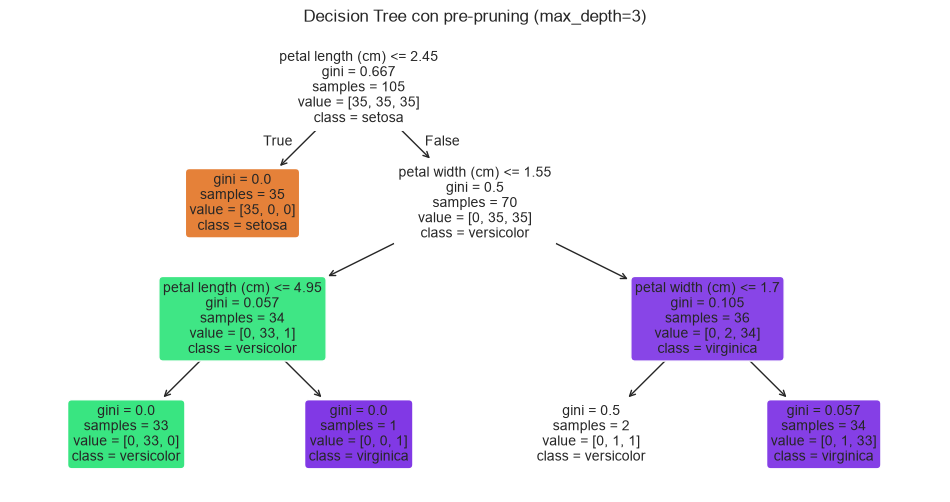

Test accuracy: completo=0.9333 vs potato=0.9778


In [10]:
pruned_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)

plt.figure(figsize=(12, 6))
plot_tree(pruned_tree, feature_names=feature_names, class_names=list(class_names), filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree con pre-pruning (max_depth=3)")
plt.show()
print(f"Test accuracy: completo={full_tree.score(X_test, y_test):.4f} vs potato={pruned_tree.score(X_test, y_test):.4f}")

## 2.3 Post-Pruning: Cost Complexity Pruning (CCP)
Si fa crescere l'albero completo e poi si **tagliano** i rami meno utili. Si minimizza

$$R_\alpha(T) = R(T) + \alpha\,|T|$$

dove $R(T)$ è l'errore di impurità delle foglie e $|T|$ il numero di foglie. Più **$\alpha$ è grande**, più l'albero viene potato (α=0 → albero completo). `cost_complexity_pruning_path` restituisce gli α "critici" a cui cambia la struttura.

Valori di alpha: [0.     0.009  0.0185 0.2789]


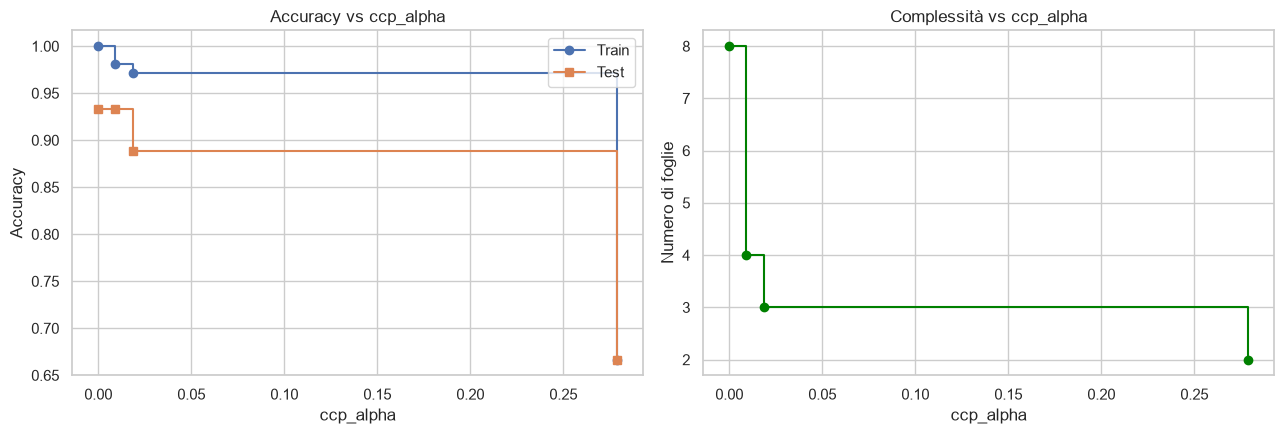

In [11]:
path = DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = np.unique(path.ccp_alphas)[:-1]   # l'ultimo alpha pota tutto fino alla sola radice: lo escludiamo
print("Valori di alpha:", ccp_alphas.round(4))

alberi = [DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a).fit(X_train, y_train) for a in ccp_alphas]
train_scores = [t.score(X_train, y_train) for t in alberi]
test_scores = [t.score(X_test, y_test) for t in alberi]
n_foglie = [t.get_n_leaves() for t in alberi]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ccp_alphas, train_scores, marker="o", drawstyle="steps-post", label="Train")
axes[0].plot(ccp_alphas, test_scores, marker="s", drawstyle="steps-post", label="Test")
axes[0].set_xlabel("ccp_alpha"); axes[0].set_ylabel("Accuracy"); axes[0].set_title("Accuracy vs ccp_alpha"); axes[0].legend()
axes[1].plot(ccp_alphas, n_foglie, marker="o", drawstyle="steps-post", color="green")
axes[1].set_xlabel("ccp_alpha"); axes[1].set_ylabel("Numero di foglie"); axes[1].set_title("Complessità vs ccp_alpha")
plt.tight_layout(); plt.show()

**Scelta di alpha:** il test set non va usato per scegliere gli iperparametri (sarebbe leakage). Qui lo usiamo a scopo *didattico* per il grafico; nella pratica si sceglie $\alpha$ con la **cross-validation sul solo train**.

In [12]:
from sklearn.model_selection import cross_val_score

cv_means = [cross_val_score(DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a), X_train, y_train, cv=5).mean()
            for a in ccp_alphas]
best_alpha = ccp_alphas[int(np.argmax(cv_means))]   # a parità prende l'alpha più piccolo
# per preferire alberi più semplici a parità di CV si potrebbe scegliere l'alpha più grande tra i migliori
best_ccp = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=best_alpha).fit(X_train, y_train)
print(f"alpha scelto (5-fold CV sul train) = {best_alpha:.4f} | foglie={best_ccp.get_n_leaves()} | test acc={best_ccp.score(X_test, y_test):.4f}")

alpha scelto (5-fold CV sul train) = 0.0185 | foglie=3 | test acc=0.8889


# Sezione 3 — Interpretabilità e Feature Importance

`feature_importances_` = **Gini importance**: per ogni feature, la riduzione totale di impurità (pesata per il numero di campioni) ottenuta negli split che la usano, normalizzata a somma 1.

In [13]:
importanze = pd.DataFrame({"feature": feature_names, "importanza": pruned_tree.feature_importances_}) \
               .sort_values("importanza", ascending=False).reset_index(drop=True)
display(importanze.round(4))
print("Somma importanze:", importanze["importanza"].sum().round(4))

,feature,importanza
0,petal length (cm),0.5509
1,petal width (cm),0.4491
2,sepal width (cm),0.0000
3,sepal length (cm),0.0000


Somma importanze: 1.0


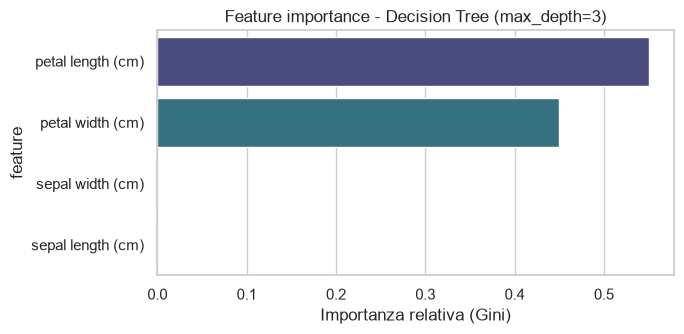

In [14]:
plt.figure(figsize=(7, 3.5))
sns.barplot(data=importanze, x="importanza", y="feature", hue="feature", palette="viridis", legend=False)
plt.title("Feature importance - Decision Tree (max_depth=3)")
plt.xlabel("Importanza relativa (Gini)")
plt.tight_layout(); plt.show()

Le feature del **petalo** dominano: sono quelle che separano meglio le tre specie (e infatti compaiono vicino alla radice).

> **Attenzione:** la Gini importance è calcolata sul training set e può favorire feature continue/con molti valori distinti; per una stima più robusta si può usare `sklearn.inspection.permutation_importance` sul test set. Inoltre feature correlate si "dividono" l'importanza.

In [15]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(pruned_tree, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE)
pd.DataFrame({"feature": feature_names, "perm_importance_media": perm.importances_mean.round(4),
              "std": perm.importances_std.round(4)}).sort_values("perm_importance_media", ascending=False)

,feature,perm_importance_media,std
2,petal length (cm),0.5193,0.0690
3,petal width (cm),0.1526,0.0375
1,sepal width (cm),0.0000,0.0000
0,sepal length (cm),0.0000,0.0000


# Sezione 4 — Estensione ensemble: Random Forest

## 4.1 Dal singolo albero alla foresta
Un singolo albero ha **alta varianza**: piccoli cambiamenti nei dati producono alberi molto diversi. La **Random Forest** riduce la varianza combinando molti alberi *decorrelati*:

1. **Bagging (bootstrap aggregating):** ogni albero è addestrato su un campione bootstrap (estratto con reinserimento) del training set;
2. **Selezione casuale delle feature:** a ogni split si considera solo un sottoinsieme casuale di feature (`max_features='sqrt'` per la classificazione);
3. **Aggregazione:** la predizione finale è il **voto di maggioranza** (o la media delle probabilità) degli alberi.

Si perde l'interpretabilità diretta del singolo albero, ma si guadagna in accuratezza e robustezza.

## 4.2 Addestramento e confronto

Random Forest - accuracy test: 0.8889
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.78      0.93      0.85        15
   virginica       0.92      0.73      0.81        15

    accuracy                           0.89        45
   macro avg       0.90      0.89      0.89        45
weighted avg       0.90      0.89      0.89        45



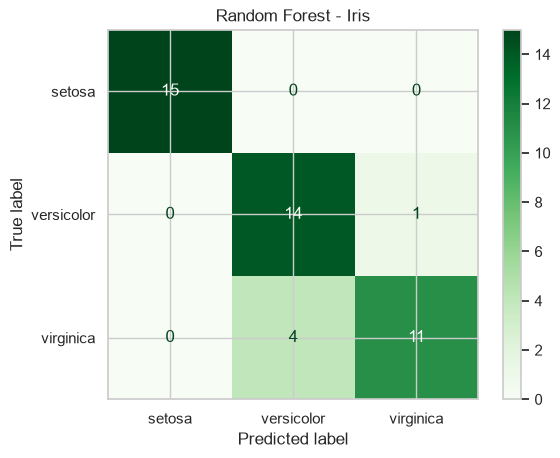

In [16]:
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print(f"Random Forest - accuracy test: {accuracy_score(y_test, y_pred_rf):.4f}")
print(classification_report(y_test, y_pred_rf, target_names=class_names))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=class_names, cmap="Greens")
plt.title("Random Forest - Iris"); plt.show()

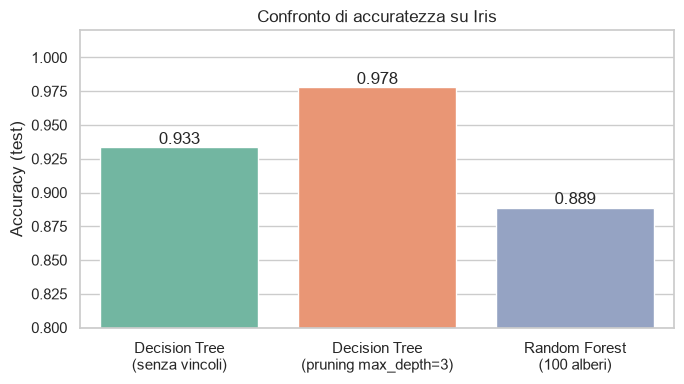

In [17]:
confronto = pd.DataFrame({
    "modello": ["Decision Tree\n(senza vincoli)", "Decision Tree\n(pruning max_depth=3)", "Random Forest\n(100 alberi)"],
    "accuracy_test": [full_tree.score(X_test, y_test), pruned_tree.score(X_test, y_test), rf.score(X_test, y_test)],
})
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=confronto, x="modello", y="accuracy_test", hue="modello", palette="Set2", legend=False)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f")
plt.ylim(0.8, 1.02); plt.ylabel("Accuracy (test)"); plt.xlabel("")
plt.title("Confronto di accuratezza su Iris"); plt.tight_layout(); plt.show()

> Su un test set di soli 45 campioni, una differenza di 1 campione = 2.2 punti percentuali: i confronti su Iris sono poco significativi. Per un confronto affidabile usa la cross-validation (cella seguente).

In [18]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
modelli_cv = {
    "DT senza vincoli": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "DT pruning (depth=3)": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
}
for nome, m in modelli_cv.items():
    s = cross_val_score(m, X, y, cv=skf)
    print(f"{nome:<22} accuracy CV 10-fold: {s.mean():.4f} ± {s.std():.4f}")

DT senza vincoli       accuracy CV 10-fold: 0.9333 ± 0.0516
DT pruning (depth=3)   accuracy CV 10-fold: 0.9400 ± 0.0554


Random Forest          accuracy CV 10-fold: 0.9533 ± 0.0521


## 4.3 Un singolo albero della foresta
`rf.estimators_` è la lista dei 100 alberi. Ognuno è stato addestrato su un campione bootstrap e con split su sottoinsiemi casuali di feature, quindi **è diverso dagli altri** (e di solito più "strano" di un albero ottimizzato).

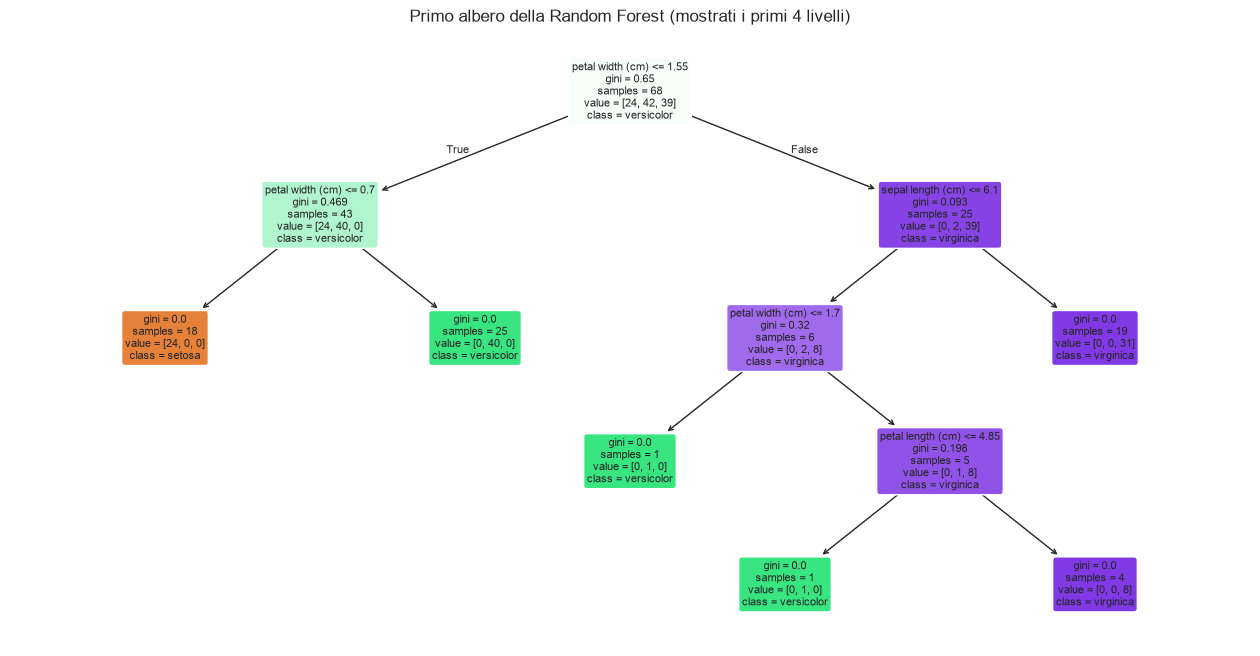

Profondità albero #0: 4 | foglie: 6
Profondità media nella foresta: 4.56


In [19]:
albero_0 = rf.estimators_[0]
plt.figure(figsize=(16, 8))
plot_tree(albero_0, feature_names=feature_names, class_names=list(class_names),
          filled=True, rounded=True, fontsize=8, max_depth=4)
plt.title("Primo albero della Random Forest (mostrati i primi 4 livelli)")
plt.show()
print("Profondità albero #0:", albero_0.get_depth(), "| foglie:", albero_0.get_n_leaves())
print("Profondità media nella foresta:", np.mean([t.get_depth() for t in rf.estimators_]).round(2))

### Feature importance: singolo albero della foresta vs ensemble

,albero #0 della foresta,Random Forest (media 100 alberi),Decision Tree (depth=3)
feature,,,
sepal length (cm),0.0089,0.1206,0.0000
sepal width (cm),0.0000,0.0243,0.0000
petal length (cm),0.0261,0.4002,0.5509
petal width (cm),0.9651,0.4549,0.4491


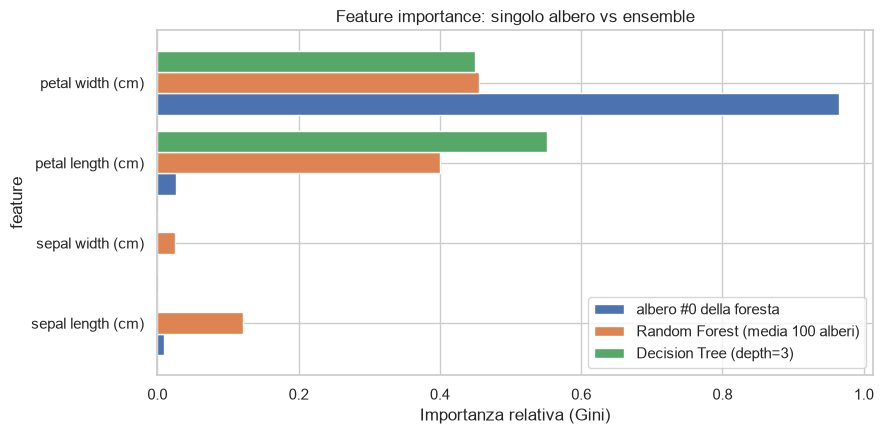

In [20]:
imp_df = pd.DataFrame({
    "feature": feature_names,
    "albero #0 della foresta": albero_0.feature_importances_,
    "Random Forest (media 100 alberi)": rf.feature_importances_,
    "Decision Tree (depth=3)": pruned_tree.feature_importances_,
}).set_index("feature")
display(imp_df.round(4))

imp_df.plot(kind="barh", figsize=(9, 4.5), width=0.8)
plt.xlabel("Importanza relativa (Gini)"); plt.title("Feature importance: singolo albero vs ensemble")
plt.tight_layout(); plt.show()

L'importanza del **singolo albero** della foresta può essere molto diversa da quella dell'ensemble (alta varianza), mentre la media su 100 alberi è **stabile** e più affidabile: un altro vantaggio della foresta.

Possiamo anche vedere la variabilità tra alberi:

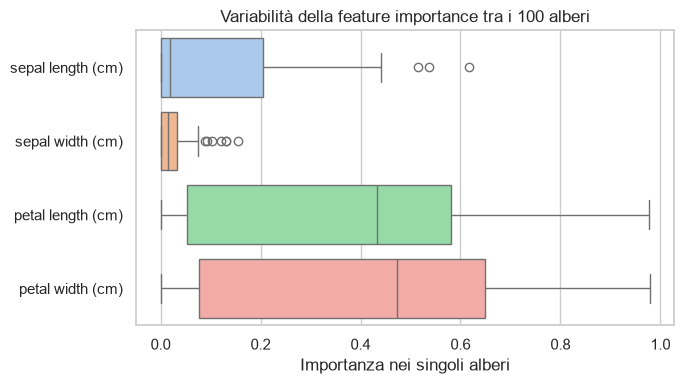

In [21]:
tutte = np.array([t.feature_importances_ for t in rf.estimators_])
plt.figure(figsize=(7, 4))
sns.boxplot(data=pd.DataFrame(tutte, columns=feature_names), orient="h", palette="pastel")
plt.xlabel("Importanza nei singoli alberi"); plt.title("Variabilità della feature importance tra i 100 alberi")
plt.tight_layout(); plt.show()

## Bonus — `DecisionTreeRegressor`
Gli alberi funzionano anche per la **regressione**: la foglia predice la *media* dei valori target dei suoi campioni e il criterio è l'errore quadratico (MSE). Esempio rapido su `load_diabetes()`, con un singolo regressore a una sola feature per visualizzare la funzione "a gradini".

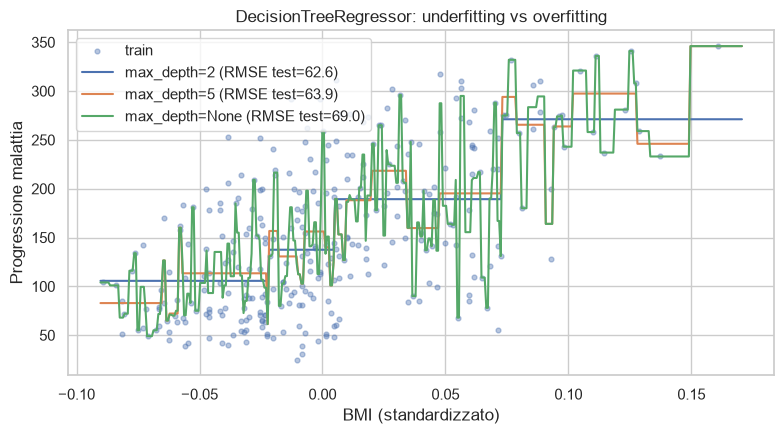

In [22]:
diab = load_diabetes()
Xd = diab.data[:, [2]]            # una sola feature (BMI) per poterla disegnare
yd = diab.target
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.3, random_state=RANDOM_STATE)

xs = np.linspace(Xd.min(), Xd.max(), 400).reshape(-1, 1)
plt.figure(figsize=(8, 4.5))
plt.scatter(Xd_tr, yd_tr, s=12, alpha=0.4, label="train")
for depth in [2, 5, None]:
    reg = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE).fit(Xd_tr, yd_tr)
    rmse = mean_squared_error(yd_te, reg.predict(Xd_te)) ** 0.5
    plt.plot(xs, reg.predict(xs), label=f"max_depth={depth} (RMSE test={rmse:.1f})")
plt.xlabel("BMI (standardizzato)"); plt.ylabel("Progressione malattia"); plt.legend(); plt.title("DecisionTreeRegressor: underfitting vs overfitting")
plt.tight_layout(); plt.show()

## Riepilogo
- **Gini vs Entropia:** prestazioni quasi equivalenti; Gini è il default (CART).
- **Overfitting:** un albero senza vincoli azzera l'errore di training; si controlla con **pre-pruning** (`max_depth`, `min_samples_split`, `min_samples_leaf`) o **post-pruning** (`ccp_alpha`, scelto con CV).
- **Interpretabilità:** `plot_tree`, `export_text` e `feature_importances_` (meglio affiancata da `permutation_importance`).
- **Random Forest:** bagging + feature casuali → meno varianza, importanze più stabili; si perde la leggibilità del singolo albero.
- **Nessuno scaling necessario.**

**Esercizi proposti:** usa `GridSearchCV` su `max_depth`/`min_samples_leaf`; prova `load_wine()` o `load_breast_cancer()` (dove l'overfitting è più evidente); varia `n_estimators` e `max_features` della foresta e osserva l'**OOB score** (`oob_score=True`).